# Credit Card Fraud Detection — End-to-End

**Goal:** flag fraudulent card transactions in a dataset where fraud is ~0.17% of all rows.

**Dataset:** [Kaggle — Credit Card Fraud Detection (ULB)](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud). 284,807 transactions over 2 days; `V1–V28` are PCA components, plus `Time`, `Amount`, `Class` (1 = fraud).

**What this notebook shows**
1. EDA on a heavily imbalanced problem
2. A **time-based split** (train on the past, test on the future, like production)
3. A logistic-regression baseline vs. LightGBM
4. Evaluation with **precision-recall**, since accuracy is meaningless at 0.17% positives
5. A **cost-based decision threshold** (missed fraud costs the transaction amount; a false alarm costs a manual review)
6. Explaining the model with SHAP

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (average_precision_score, roc_auc_score,
                             precision_recall_curve, confusion_matrix,
                             classification_report)

RANDOM_STATE = 42
import glob
# Works on Kaggle (dataset attached as input) or locally (file in ./data/)
_found = glob.glob('/kaggle/input/**/creditcard.csv', recursive=True)
DATA_PATH = _found[0] if _found else "data/creditcard.csv"
print(DATA_PATH)
pd.set_option("display.float_format", "{:.4f}".format)

/kaggle/input/datasets/mlg-ulb/creditcardfraud/creditcard.csv


## 1. Load and inspect

In [2]:
df = pd.read_csv(DATA_PATH)
print(df.shape)
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
df.head()

(284807, 31)
Missing values: 0
Duplicate rows: 1081


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0000,-1.3598,-0.0728,2.5363,1.3782,-0.3383,0.4624,0.2396,0.0987,0.3638,...,-0.0183,0.2778,-0.1105,0.0669,0.1285,-0.1891,0.1336,-0.0211,149.6200,0
1,0.0000,1.1919,0.2662,0.1665,0.4482,0.0600,-0.0824,-0.0788,0.0851,-0.2554,...,-0.2258,-0.6387,0.1013,-0.3398,0.1672,0.1259,-0.0090,0.0147,2.6900,0
2,1.0000,-1.3584,-1.3402,1.7732,0.3798,-0.5032,1.8005,0.7915,0.2477,-1.5147,...,0.2480,0.7717,0.9094,-0.6893,-0.3276,-0.1391,-0.0554,-0.0598,378.6600,0
3,1.0000,-0.9663,-0.1852,1.7930,-0.8633,-0.0103,1.2472,0.2376,0.3774,-1.3870,...,-0.1083,0.0053,-0.1903,-1.1756,0.6474,-0.2219,0.0627,0.0615,123.5000,0
4,2.0000,-1.1582,0.8777,1.5487,0.4030,-0.4072,0.0959,0.5929,-0.2705,0.8177,...,-0.0094,0.7983,-0.1375,0.1413,-0.2060,0.5023,0.2194,0.2152,69.9900,0


In [3]:
counts = df["Class"].value_counts()
print(counts)
print(f"Fraud rate: {df['Class'].mean():.4%}")

Class
0    284315
1       492
Name: count, dtype: int64
Fraud rate: 0.1727%


## 2. EDA

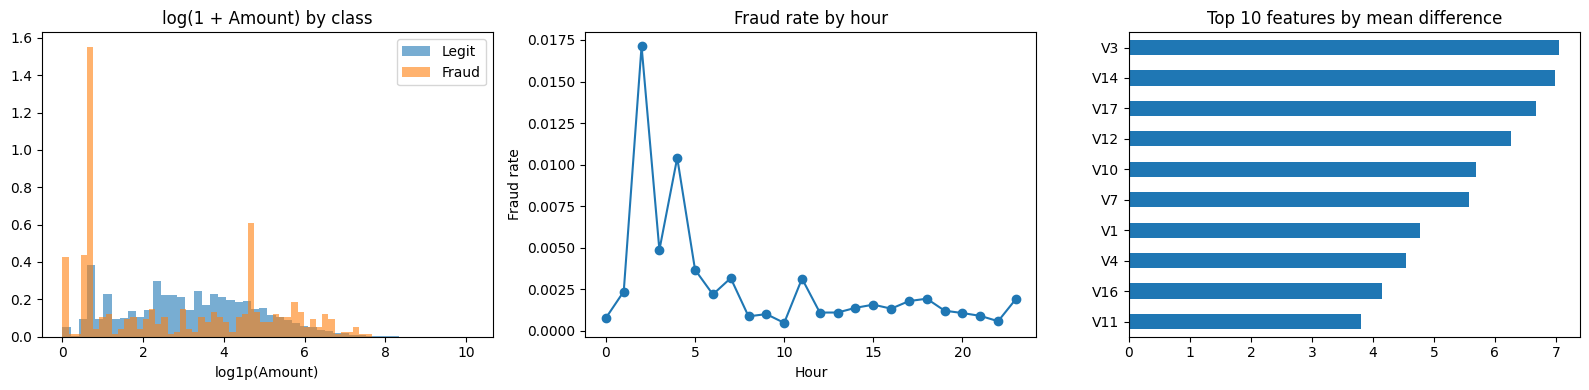

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Amount by class (log scale — amounts are heavily skewed)
for label, name in [(0, "Legit"), (1, "Fraud")]:
    axes[0].hist(np.log1p(df.loc[df.Class == label, "Amount"]),
                 bins=50, alpha=0.6, density=True, label=name)
axes[0].set(title="log(1 + Amount) by class", xlabel="log1p(Amount)")
axes[0].legend()

# Fraud rate by hour of day
hour = (df["Time"] // 3600) % 24
df.groupby(hour)["Class"].mean().plot(ax=axes[1], marker="o")
axes[1].set(title="Fraud rate by hour", xlabel="Hour", ylabel="Fraud rate")

# Which PCA features separate the classes most?
sep = (df.groupby("Class")[[f"V{i}" for i in range(1, 29)]].mean()
         .diff().iloc[-1].abs().sort_values(ascending=False))
sep.head(10).plot.barh(ax=axes[2])
axes[2].set(title="Top 10 features by mean difference")
axes[2].invert_yaxis()
plt.tight_layout(); plt.show()

**EDA findings**
- **Fraud is extremely rare:** 492 of 284,807 transactions (0.17%), so accuracy is a useless metric here.
- **Fraud amounts cluster at both ends:** a large spike at very small amounts (around $1, consistent with card-testing) and a second cluster near $100.
- **Fraud rate peaks in the early hours:** about 1.7% at hour 2 and about 1% at hour 4, roughly 6–10× the average. (`Time` counts seconds from the first transaction, so "hour" is approximate, not true clock time.)
- **V3, V14, V17 and V12** show the largest mean difference between fraud and legit transactions.
- 1,081 duplicate rows exist. They're kept, since identical transactions can legitimately repeat.

## 3. Feature engineering + time-based split

A random split would let the model see "future" fraud patterns during training. Sorting by `Time` and splitting 70 / 15 / 15 mimics production: train on the past, tune on the recent past, test on the future.

In [5]:
def add_features(d):
    d = d.copy()
    d["hour"] = (d["Time"] // 3600) % 24
    d["is_night"] = d["hour"].between(0, 5).astype(int)
    d["log_amount"] = np.log1p(d["Amount"])
    d["amount_is_round"] = (d["Amount"] % 1 == 0).astype(int)
    return d

df = add_features(df).sort_values("Time").reset_index(drop=True)
FEATURES = [c for c in df.columns if c not in ("Class", "Time", "Amount")]

n = len(df)
train = df.iloc[: int(n * 0.70)]
val   = df.iloc[int(n * 0.70): int(n * 0.85)]
test  = df.iloc[int(n * 0.85):]

X_tr, y_tr = train[FEATURES], train["Class"]
X_va, y_va = val[FEATURES],   val["Class"]
X_te, y_te = test[FEATURES],  test["Class"]

for name, y in [("train", y_tr), ("val", y_va), ("test", y_te)]:
    print(f"{name:5s} rows={len(y):>7,}  frauds={y.sum():>4}  rate={y.mean():.4%}")

train rows=199,364  frauds= 384  rate=0.1926%
val   rows= 42,721  frauds=  56  rate=0.1311%
test  rows= 42,722  frauds=  52  rate=0.1217%


## 4. Baseline: logistic regression (class-weighted)

In [6]:
baseline = make_pipeline(StandardScaler(),
                         LogisticRegression(class_weight="balanced", max_iter=2000))
baseline.fit(X_tr, y_tr)
p_va_base = baseline.predict_proba(X_va)[:, 1]
print(f"Baseline  PR-AUC={average_precision_score(y_va, p_va_base):.4f}  "
      f"ROC-AUC={roc_auc_score(y_va, p_va_base):.4f}")

Baseline  PR-AUC=0.8207  ROC-AUC=0.9814


## 5. LightGBM

`scale_pos_weight` handles the imbalance without resampling (SMOTE on a time-ordered problem can leak and inflate scores). Early stopping uses the validation set's average precision.

In [7]:
pos_weight = (y_tr == 0).sum() / (y_tr == 1).sum()

model = lgb.LGBMClassifier(
    n_estimators=2000,
    learning_rate=0.03,
    num_leaves=31,
    min_child_samples=50,
    subsample=0.8, subsample_freq=1,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    scale_pos_weight=pos_weight,
    random_state=RANDOM_STATE,
    verbose=-1,
)
model.fit(X_tr, y_tr,
          eval_set=[(X_va, y_va)],
          eval_metric="average_precision",
          callbacks=[lgb.early_stopping(100, verbose=False)])

p_va = model.predict_proba(X_va)[:, 1]
print(f"Best iteration: {model.best_iteration_}")
print(f"LightGBM  PR-AUC={average_precision_score(y_va, p_va):.4f}  "
      f"ROC-AUC={roc_auc_score(y_va, p_va):.4f}")

Best iteration: 750
LightGBM  PR-AUC=0.8468  ROC-AUC=0.9836


## 6. Choosing a decision threshold by cost

A fixed 0.5 cut-off ignores the business trade-off. Here:
- **Missed fraud (FN)** costs the transaction amount
- **False alarm (FP)** costs a manual review, set to **$5** (an assumption, adjust it)

The threshold is picked on **validation** data and then applied unchanged to **test**.

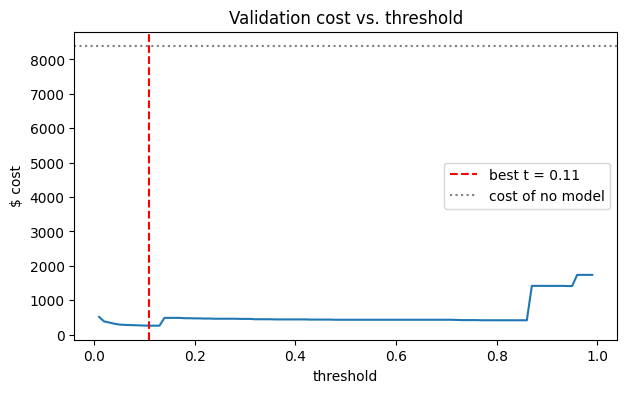

Chosen threshold: 0.11


In [8]:
REVIEW_COST = 5.0

def total_cost(y, p, amount, t):
    pred = p >= t
    fn_cost = amount[(y == 1) & ~pred].sum()
    fp_cost = REVIEW_COST * ((y == 0) & pred).sum()
    return fn_cost + fp_cost

amt_va = val["Amount"].values
thresholds = np.linspace(0.01, 0.99, 99)
costs = [total_cost(y_va.values, p_va, amt_va, t) for t in thresholds]
best_t = thresholds[int(np.argmin(costs))]

plt.figure(figsize=(7, 4))
plt.plot(thresholds, costs)
plt.axvline(best_t, ls="--", c="r", label=f"best t = {best_t:.2f}")
plt.axhline(amt_va[y_va.values == 1].sum(), ls=":", c="gray", label="cost of no model")
plt.title("Validation cost vs. threshold"); plt.xlabel("threshold"); plt.ylabel("$ cost")
plt.legend(); plt.show()
print(f"Chosen threshold: {best_t:.2f}")

## 7. Final evaluation on the held-out test set

In [9]:
p_te = model.predict_proba(X_te)[:, 1]
p_te_base = baseline.predict_proba(X_te)[:, 1]
pred_te = (p_te >= best_t).astype(int)
amt_te = test["Amount"].values

results = pd.DataFrame({
    "PR-AUC":  [average_precision_score(y_te, p_te_base), average_precision_score(y_te, p_te)],
    "ROC-AUC": [roc_auc_score(y_te, p_te_base),           roc_auc_score(y_te, p_te)],
}, index=["Logistic regression", "LightGBM"])
display(results)

print(classification_report(y_te, pred_te, digits=4, target_names=["legit", "fraud"]))
tn, fp, fn, tp = confusion_matrix(y_te, pred_te).ravel()
print(f"TP={tp}  FP={fp}  FN={fn}  TN={tn}")

no_model = amt_te[y_te.values == 1].sum()
with_model = total_cost(y_te.values, p_te, amt_te, best_t)
caught = amt_te[(y_te.values == 1) & (pred_te == 1)].sum()
print(f"Fraud $ caught: ${caught:,.0f} of ${no_model:,.0f} ({caught / no_model:.1%})")
print(f"Total cost with model: ${with_model:,.0f} vs ${no_model:,.0f} with no model")

,PR-AUC,ROC-AUC
Logistic regression,0.6909,0.9780
LightGBM,0.7404,0.9520


              precision    recall  f1-score   support

       legit     0.9997    0.9994    0.9995     42670
       fraud     0.6032    0.7308    0.6609        52

    accuracy                         0.9991     42722
   macro avg     0.8014    0.8651    0.8302     42722
weighted avg     0.9992    0.9991    0.9991     42722

TP=38  FP=25  FN=14  TN=42645
Fraud $ caught: $3,549 of $6,169 (57.5%)
Total cost with model: $2,745 vs $6,169 with no model


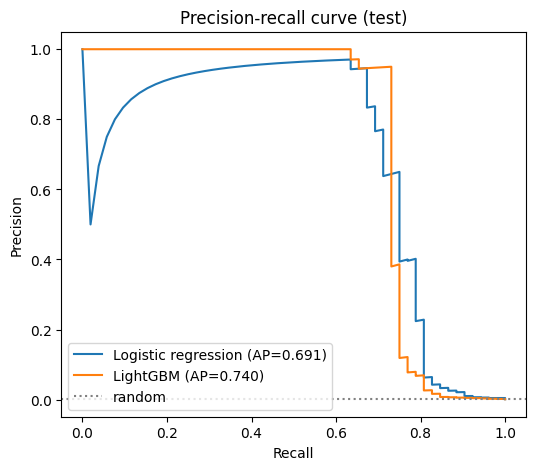

In [10]:
fig, ax = plt.subplots(figsize=(6, 5))
for name, p in [("Logistic regression", p_te_base), ("LightGBM", p_te)]:
    prec, rec, _ = precision_recall_curve(y_te, p)
    ax.plot(rec, prec, label=f"{name} (AP={average_precision_score(y_te, p):.3f})")
ax.axhline(y_te.mean(), ls=":", c="gray", label="random")
ax.set(title="Precision-recall curve (test)", xlabel="Recall", ylabel="Precision")
ax.legend(); plt.show()

## 8. What drives the predictions (SHAP)

/usr/local/lib/python3.13/dist-packages/shap/explainers/_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


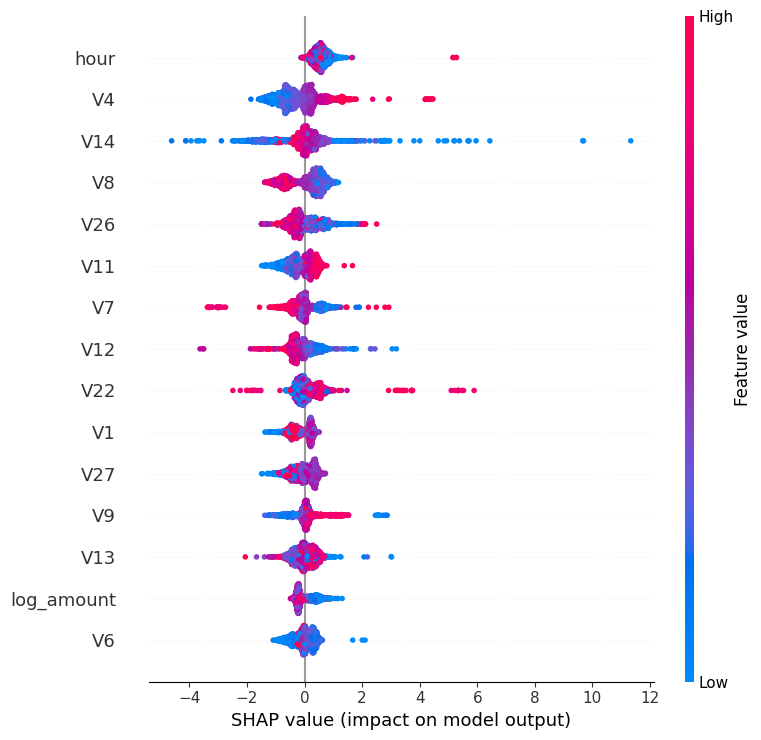

In [11]:
try:
    import shap
    sample = X_te.sample(min(2000, len(X_te)), random_state=RANDOM_STATE)
    explainer = shap.TreeExplainer(model)
    sv = explainer.shap_values(sample)
    sv = sv[1] if isinstance(sv, list) else sv
    shap.summary_plot(sv, sample, max_display=15)
except ImportError:
    print("pip install shap  — falling back to LightGBM gain importance")
    imp = pd.Series(model.booster_.feature_importance("gain"), index=FEATURES)
    imp.sort_values().tail(15).plot.barh(figsize=(6, 5), title="Feature importance (gain)")
    plt.show()

**SHAP takeaways**
- **V14** has the strongest single effect: low values push predictions sharply toward fraud, consistent with the EDA.
- **High V4** values also increase fraud risk.
- The engineered **hour** feature ranks #1 overall, matching the early-hours fraud spike in the EDA. With only 2 days of data, this pattern needs validating on a longer period.
- **Smaller amounts** push slightly toward fraud, which fits the finding that the model misses more high-value fraud.

## 9. Results and takeaways

| Model | Test PR-AUC | Test ROC-AUC |
|---|---|---|
| Logistic regression | 0.691 | 0.978 |
| **LightGBM** | **0.740** | 0.952 |

- At the cost-optimal threshold, LightGBM catches **73% of frauds (38 of 52)** at **60% precision**, with 25 false alarms in 42,722 transactions.
- Total cost falls **55%**, from $6,169 with no model to $2,745.
- Logistic regression has the higher ROC-AUC, but PR-AUC shows LightGBM is better on the fraud class. At 0.12% positives, ROC-AUC mostly reflects how well legit transactions are ranked.
- The model catches 73% of fraud *cases* but only 57.5% of fraud *dollars*, so the frauds it misses tend to be larger.

**Limitations and next steps**
- The test set has only 52 frauds, so the metrics are noisy.
- Next: weight training by transaction amount to catch more high-value fraud.
- The PCA features hide raw signals. On real data I'd add velocity features (for example, card transactions in the last hour).
- The $5 review cost is an assumption and should come from the operations team. 
